# Lab Sheet 03

Harsh Saini | Roll 253028036

MCA III Semester, Session 2026-2027

Run all cells in order from this folder. Outputs below are captured from execution, not typed examples. See README for dataset sources.

## Common setup
Run once before Program 1.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Run this file or notebook from the practicals folder.
DATA = Path("datasets")
OUT = Path("outputs") / "lab_03"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 78)
pd.set_option("display.max_columns", 8)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")
np.set_printoptions(precision=3, suppress=True)
sns.set_theme(style="whitegrid", font_scale=0.9)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f"{name}.png", dpi=160)
    plt.show()

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score)
import joblib

def metrics(actual, predicted):
    mse = mean_squared_error(actual, predicted)
    return {"MAE": mean_absolute_error(actual, predicted),
            "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2_score(actual, predicted)}


## Program 01: Load a regression dataset using the Pandas library.

**Procedure:** Load the bundled diabetes CSV using Pandas.

In [2]:
try:
    data = pd.read_csv(DATA / "diabetes.csv")
except (FileNotFoundError, pd.errors.ParserError) as error:
    raise RuntimeError("Check datasets/diabetes.csv") from error
print("Dataset: scikit-learn diabetes (real clinical data)")
print("Shape:", data.shape)


Dataset: scikit-learn diabetes (real clinical data)
Shape: (442, 11)


**Observation:** The target measures disease progression one year after baseline. The ten supplied features are already scaled in this built-in dataset.

## Program 02: Display the first and last five records of the dataset.

**Procedure:** Display head() and tail().

In [3]:
print("First five records:")
print(data.head())
print("Last five records:")
print(data.tail())


First five records:
     age    sex    bmi     bp  ...     s4     s5     s6  target
0  0.038  0.051  0.062  0.022  ... -0.003  0.020 -0.018 151.000
1 -0.002 -0.045 -0.051 -0.026  ... -0.039 -0.068 -0.092  75.000
2  0.085  0.051  0.044 -0.006  ... -0.003  0.003 -0.026 141.000
3 -0.089 -0.045 -0.012 -0.037  ...  0.034  0.023 -0.009 206.000
4  0.005 -0.045 -0.036  0.022  ... -0.003 -0.032 -0.047 135.000

[5 rows x 11 columns]
Last five records:
       age    sex    bmi     bp  ...     s4     s5     s6  target
437  0.042  0.051  0.020  0.060  ... -0.003  0.031  0.007 178.000
438 -0.006  0.051 -0.016 -0.068  ...  0.034 -0.018  0.044 104.000
439  0.042  0.051 -0.016  0.017  ... -0.011 -0.047  0.015 132.000
440 -0.045 -0.045  0.039  0.001  ...  0.027  0.045 -0.026 220.000
441 -0.045 -0.045 -0.073 -0.081  ... -0.039 -0.004  0.003  57.000

[5 rows x 11 columns]


**Observation:** The first and last records confirm that the CSV loaded correctly.

## Program 03: Explore dataset information and descriptive statistics.

**Procedure:** Inspect structure, descriptive statistics, and missing counts.

In [4]:
data.info()
print("Statistics:")
print(data.describe().round(2).T)
print("Total missing:", data.isna().sum().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
Statistics:
         count    mean    std    min    25%     50%     75%     max
age    442.000  -0.000  0.050 -0.110 -0.040   0.010   0.040   0.110
sex    442.000   0.000  0.050 -0.040 -0.040  -0.040   0.050   0.050
bmi    442.000  -0.000  0.050 -0.090 -0.030  -0.010   0.030   0.170
bp     442.000  -0.000  0.050 -0.110 -0.040  -0.010   0.040   0.130
s1     442.000  -0.0

**Observation:** There are 442 complete records and ten input features.

## Program 04: Identify input (independent) and output (dependent) variables.

**Procedure:** Separate independent features and the dependent target.

In [5]:
X = data.drop(columns="target")
y = data["target"]
print("Inputs:", X.columns.tolist())
print("Output:", y.name)
print("Simple regression input: bmi")


Inputs: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
Output: target
Simple regression input: bmi


**Observation:** The target is excluded from X to prevent target leakage.

## Program 05: Split the dataset into training and testing sets.

**Procedure:** Split indices with a fixed seed and select matching feature and target rows.

In [6]:
train_index, test_index = train_test_split(
    np.arange(len(data)), test_size=0.20, random_state=42)
X_train, X_test = X.iloc[train_index], X.iloc[test_index]
y_train, y_test = y.iloc[train_index], y.iloc[test_index]
bmi_train, bmi_test = X_train[["bmi"]], X_test[["bmi"]]
print("Training:", X_train.shape, "Testing:", X_test.shape)
print("Overlapping indices:",
      len(set(train_index).intersection(test_index)))


Training: (353, 10) Testing: (89, 10)
Overlapping indices: 0


**Observation:** The same split is reused for model comparisons.

## Program 06: Implement a Simple Linear Regression model.

**Procedure:** Create a LinearRegression estimator for BMI.

In [7]:
simple = LinearRegression()
print(simple)
print("Input feature:", bmi_train.columns.tolist())


LinearRegression()
Input feature: ['bmi']


**Observation:** A simple linear model uses one input feature.

## Program 07: Train the Linear Regression model using the training dataset.

**Procedure:** Fit the simple model on the training split.

In [8]:
simple.fit(bmi_train, y_train)
print("Model trained on", len(bmi_train), "records")
print("Coefficient:", simple.coef_)
print("Intercept:", round(simple.intercept_, 3))


Model trained on 353 records
Coefficient: [998.578]
Intercept: 152.003


**Observation:** The model estimates a straight-line relationship between BMI and progression.

## Program 08: Predict output values using the trained Linear Regression model.

**Procedure:** Predict the held-out BMI values.

In [9]:
simple_pred = simple.predict(bmi_test)
print("First predictions:", np.round(simple_pred[:8], 3))
print("Test R2:", round(r2_score(y_test, simple_pred), 3))


First predictions: [145.806 188.857 147.959 203.925 131.815 127.509 322.316 197.468]
Test R2: 0.233


**Observation:** Predictions are evaluated on rows not used for fitting.

## Program 09: Visualize the Linear Regression line using Matplotlib.

**Procedure:** Plot test observations and the fitted regression line.

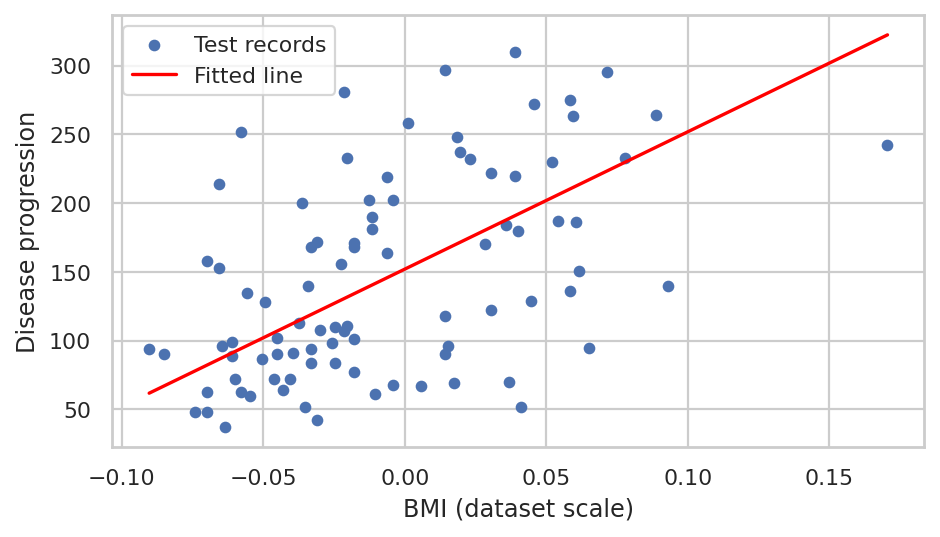

In [10]:
line_x = np.linspace(X["bmi"].min(), X["bmi"].max(), 100)
line_frame = pd.DataFrame({"bmi": line_x})
plt.figure(figsize=(6, 3.5))
plt.scatter(bmi_test["bmi"], y_test, label="Test records", s=18)
plt.plot(line_x, simple.predict(line_frame), color="red",
         label="Fitted line")
plt.xlabel("BMI (dataset scale)")
plt.ylabel("Disease progression")
plt.legend()
save_plot("09_regression_line")


**Observation:** The line describes a trend, while individual targets still vary widely.

## Program 10: Compare actual and predicted values.

**Procedure:** Place actual values, predictions, and residuals in a table.

In [11]:
actual_vs_pred = pd.DataFrame({"actual": y_test.to_numpy(),
                               "predicted": simple_pred})
actual_vs_pred["error"] = (actual_vs_pred["actual"] -
                            actual_vs_pred["predicted"])
print(actual_vs_pred.head(8))


   actual  predicted    error
0 219.000    145.806   73.194
1  70.000    188.857 -118.857
2 202.000    147.959   54.041
3 230.000    203.925   26.075
4 111.000    131.815  -20.815
5  84.000    127.509  -43.509
6 242.000    322.316  -80.316
7 272.000    197.468   74.532


**Observation:** A positive residual means the model under-predicted the target.

## Program 11: Display the regression coefficient and intercept.

**Procedure:** Read coef_ and intercept_ from the fitted model.

In [12]:
print("Slope:", round(float(simple.coef_[0]), 3))
print("Intercept:", round(float(simple.intercept_), 3))
print("Equation: target = slope * bmi + intercept")


Slope: 998.578
Intercept: 152.003
Equation: target = slope * bmi + intercept


**Observation:** The slope uses the built-in dataset scale, not BMI in raw clinical units.

## Program 12: Predict the output for new user-defined input values.

**Procedure:** Create user-defined BMI values and call predict().

In [13]:
new_input = pd.DataFrame({"bmi": [0.02, 0.04]})
print("New inputs (dataset scale):")
print(new_input)
print("Predictions:", simple.predict(new_input).round(3))


New inputs (dataset scale):
    bmi
0 0.020
1 0.040
Predictions: [171.975 191.946]


**Observation:** New feature values must use the same scale as the training data.

## Program 13: Implement Multiple Linear Regression using multiple independent variables.

**Procedure:** Create a LinearRegression estimator for all input columns.

In [14]:
multiple = LinearRegression()
print("Multiple regression feature count:", X_train.shape[1])
print(multiple)


Multiple regression feature count: 10
LinearRegression()


**Observation:** Multiple regression uses all ten independent features.

## Program 14: Train the Multiple Linear Regression model.

**Procedure:** Fit the multiple model on X_train and y_train.

In [15]:
multiple.fit(X_train, y_train)
print("Trained features:", multiple.feature_names_in_)
print("Training R2:", round(multiple.score(X_train, y_train), 3))


Trained features: ['age' 'sex' 'bmi' 'bp' 's1' 's2' 's3' 's4' 's5' 's6']
Training R2: 0.528


**Observation:** Training score describes fit to known data; testing score is needed for generalization.

## Program 15: Predict output values using the testing dataset.

**Procedure:** Predict multiple-regression targets and calculate test metrics.

In [16]:
multiple_pred = multiple.predict(X_test)
print(pd.DataFrame({"actual": y_test.to_numpy(),
                    "predicted": multiple_pred}).head(8))
print("Test metrics:")
print(pd.Series(metrics(y_test, multiple_pred)))


   actual  predicted
0 219.000    139.548
1  70.000    179.517
2 202.000    134.039
3 230.000    291.417
4 111.000    123.790
5  84.000     92.172
6 242.000    258.232
7 272.000    181.337
Test metrics:
MAE      42.794
MSE    2900.194
RMSE     53.853
R2        0.453
dtype: float64


**Observation:** All reported evaluation values use the held-out split.

## Program 16: Compare actual and predicted values graphically.

**Procedure:** Plot actual against predicted values and add a diagonal reference.

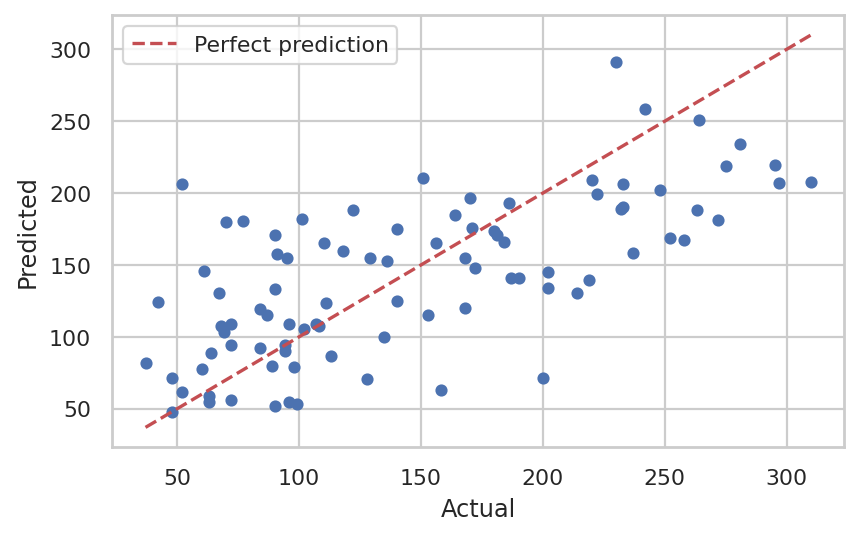

In [17]:
plt.figure(figsize=(5.5, 3.5))
plt.scatter(y_test, multiple_pred, s=20)
limits = [min(y_test.min(), multiple_pred.min()),
          max(y_test.max(), multiple_pred.max())]
plt.plot(limits, limits, "r--", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.legend()
save_plot("16_actual_predicted")


**Observation:** Points closer to the diagonal have smaller prediction errors.

## Program 17: Analyze the effect of each independent variable on prediction.

**Procedure:** Match each fitted coefficient to its feature name.

In [18]:
coefficients = pd.Series(multiple.coef_, index=X.columns)
print(coefficients.sort_values(key=abs, ascending=False))


s1    -931.489
s5     736.199
bmi    542.429
s2     518.062
bp     347.704
s4     275.318
sex   -241.964
s3     163.420
s6      48.671
age     37.904
dtype: float64


**Observation:** Coefficients are conditional associations. Correlated features can make them unstable, so they are not causal effects.

## Program 18: Implement Polynomial Regression of Degree 2.

**Procedure:** Expand one input to degree two and fit a linear estimator to the expanded features.

In [19]:
degree2 = make_pipeline(PolynomialFeatures(degree=2,
                                         include_bias=False),
                        LinearRegression())
degree2.fit(bmi_train, y_train)
pred2 = degree2.predict(bmi_test)
print("Degree 2 test metrics:")
print(pd.Series(metrics(y_test, pred2)))


Degree 2 test metrics:
MAE      52.384
MSE    4085.025
RMSE     63.914
R2        0.229
dtype: float64


**Observation:** The model includes BMI and BMI squared, fitted only on training rows.

## Program 19: Implement Polynomial Regression of Degree 3.

**Procedure:** Expand BMI through degree three and fit the model.

In [20]:
degree3 = make_pipeline(PolynomialFeatures(degree=3,
                                         include_bias=False),
                        LinearRegression())
degree3.fit(bmi_train, y_train)
pred3 = degree3.predict(bmi_test)
print("Degree 3 test metrics:")
print(pd.Series(metrics(y_test, pred3)))


Degree 3 test metrics:
MAE      52.181
MSE    4064.443
RMSE     63.753
R2        0.233
dtype: float64


**Observation:** Extra flexibility does not guarantee better held-out performance.

## Program 20: Compare Linear Regression and Polynomial Regression models.

**Procedure:** Compare metrics on the same test rows.

In [21]:
model_metrics = pd.DataFrame({
    "Linear BMI": metrics(y_test, simple_pred),
    "Polynomial 2": metrics(y_test, pred2),
    "Polynomial 3": metrics(y_test, pred3),
    "Multiple linear": metrics(y_test, multiple_pred)}).T
print(model_metrics.round(3))


                   MAE      MSE   RMSE    R2
Linear BMI      52.260 4061.826 63.732 0.233
Polynomial 2    52.384 4085.025 63.914 0.229
Polynomial 3    52.181 4064.443 63.753 0.233
Multiple linear 42.794 2900.194 53.853 0.453


**Observation:** The polynomial models use one feature; multiple regression uses ten, so its difference also reflects additional inputs.

## Program 21: Visualize Polynomial Regression curves.

**Procedure:** Draw all three fitted curves over the same BMI range.

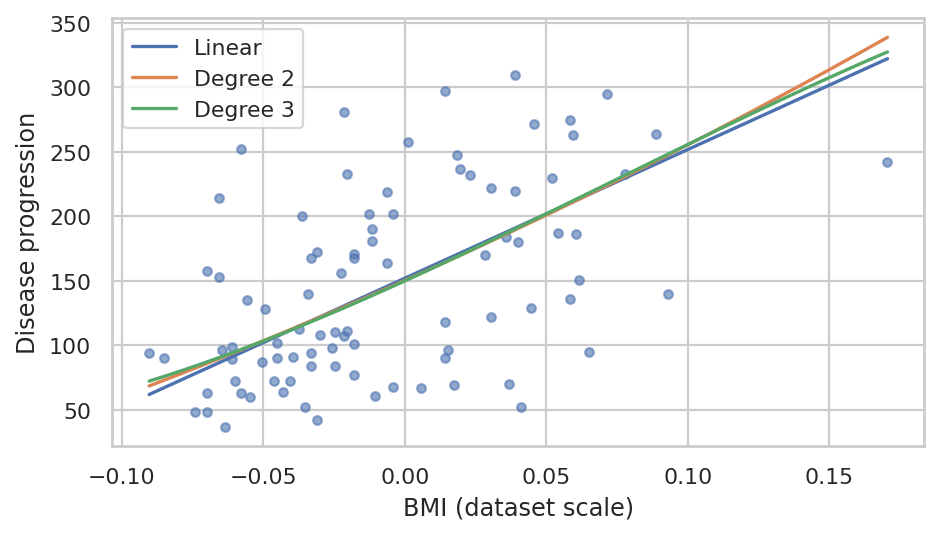

In [22]:
plt.figure(figsize=(6, 3.5))
plt.scatter(bmi_test["bmi"], y_test, s=15, alpha=0.6)
for label, model in [("Linear", simple), ("Degree 2", degree2),
                     ("Degree 3", degree3)]:
    plt.plot(line_x, model.predict(line_frame), label=label)
plt.xlabel("BMI (dataset scale)")
plt.ylabel("Disease progression")
plt.legend()
save_plot("21_polynomial_curves")


**Observation:** Curves can diverge near the ends of the observed range.

## Program 22: Predict output values using the Polynomial Regression model.

**Procedure:** Predict user-defined values with both polynomial models.

In [23]:
print(pd.DataFrame({"bmi": new_input["bmi"],
                    "degree2": degree2.predict(new_input),
                    "degree3": degree3.predict(new_input)}))


    bmi  degree2  degree3
0 0.020  170.154  170.299
1 0.040  190.577  191.306


**Observation:** Different polynomial degrees produce different estimates for the same inputs.

## Program 23: Compare prediction accuracy for different polynomial degrees.

**Procedure:** Compare RMSE and R2 for the one-feature models.

In [24]:
accuracy = model_metrics.loc[
    ["Linear BMI", "Polynomial 2", "Polynomial 3"], ["RMSE", "R2"]]
print(accuracy)
print("Smallest test RMSE:", accuracy["RMSE"].idxmin())


               RMSE    R2
Linear BMI   63.732 0.233
Polynomial 2 63.914 0.229
Polynomial 3 63.753 0.233
Smallest test RMSE: Linear BMI


**Observation:** The best result here is specific to this single held-out split; cross-validation would give a stronger comparison.

## Program 24: Calculate Mean Absolute Error (MAE).

**Procedure:** Calculate the average absolute difference between actual values and predictions.

In [25]:
mae = mean_absolute_error(y_test, multiple_pred)
print("MAE:", round(mae, 3))


MAE: 42.794


**Observation:** MAE measures average absolute error in the target units.

## Program 25: Calculate Mean Squared Error (MSE).

**Procedure:** Calculate the mean squared prediction error.

In [26]:
mse = mean_squared_error(y_test, multiple_pred)
print("MSE:", round(mse, 3))


MSE: 2900.194


**Observation:** MSE uses squared target units and gives larger errors more weight.

## Program 26: Calculate Root Mean Squared Error (RMSE).

**Procedure:** Take the square root of MSE.

In [27]:
rmse = np.sqrt(mse)
print("RMSE:", round(rmse, 3))


RMSE: 53.853


**Observation:** RMSE returns the error measure to the original target units.

## Program 27: Calculate the R-squared (R²) Score.

**Procedure:** Calculate r2_score on test values and predictions.

In [28]:
r2 = r2_score(y_test, multiple_pred)
print("R2:", round(r2, 3))


R2: 0.453


**Observation:** R2 compares squared errors against predicting the mean of the evaluated target values. It can be negative.

## Program 28: Compare the performance of Linear and Polynomial Regression using evaluation metrics.

**Procedure:** Display the full model-evaluation table.

In [29]:
print(model_metrics[["MAE", "MSE", "RMSE", "R2"]].round(3))
print("All models evaluated on", len(y_test), "test records")


                   MAE      MSE   RMSE    R2
Linear BMI      52.260 4061.826 63.732 0.233
Polynomial 2    52.384 4085.025 63.914 0.229
Polynomial 3    52.181 4064.443 63.753 0.233
Multiple linear 42.794 2900.194 53.853 0.453
All models evaluated on 89 test records


**Observation:** Lower MAE/MSE/RMSE and higher R2 indicate better fit on this test split.

## Program 29: Interpret the meaning of MSE and R² values.

**Procedure:** Print the observed values and explain what each measure means.

In [30]:
print("Multiple linear MSE:", round(mse, 3))
print("Multiple linear R2:", round(r2, 3))
print("MSE is average squared error; lower is better.")
print("R2 = 1 is perfect; 0 matches the test-mean baseline.")
print("A negative R2 is worse than that baseline.")


Multiple linear MSE: 2900.194
Multiple linear R2: 0.453
MSE is average squared error; lower is better.
R2 = 1 is perfect; 0 matches the test-mean baseline.
A negative R2 is worse than that baseline.


**Observation:** Metrics should be interpreted together with the target scale and baseline.

## Program 30: Visualize prediction errors using scatter plots.

**Procedure:** Plot residuals against fitted predictions and mark zero error.

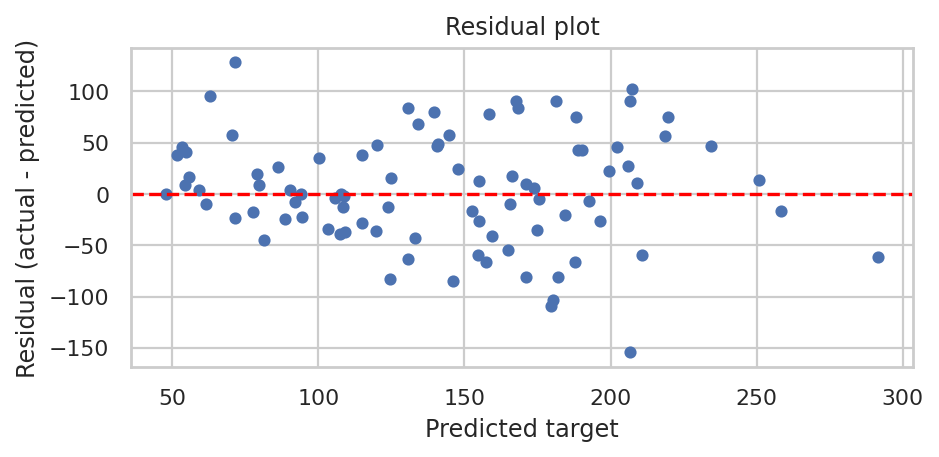

In [31]:
errors = y_test.to_numpy() - multiple_pred
plt.figure(figsize=(6, 3))
plt.scatter(multiple_pred, errors, s=20)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted target")
plt.ylabel("Residual (actual - predicted)")
plt.title("Residual plot")
save_plot("30_residuals")


**Observation:** Residual patterns may indicate a model limitation; this plot alone is not a formal diagnostic test.

## Program 31: Train the regression model using standardized features.

**Procedure:** Fit a StandardScaler plus LinearRegression pipeline.

In [32]:
scaled_model = make_pipeline(StandardScaler(), LinearRegression())
scaled_model.fit(X_train, y_train)
scaled_pred = scaled_model.predict(X_test)
print(pd.Series(metrics(y_test, scaled_pred)))


MAE      42.794
MSE    2900.194
RMSE     53.853
R2        0.453
dtype: float64


**Observation:** The scaler is fitted within the pipeline using training features only.

## Program 32: Compare model performance before and after feature scaling.

**Procedure:** Compare scaled and unscaled predictions on the identical split.

In [33]:
print(pd.DataFrame({
    "unscaled": metrics(y_test, multiple_pred),
    "scaled": metrics(y_test, scaled_pred)}).T)
print("Maximum prediction difference:",
      np.max(np.abs(multiple_pred - scaled_pred)))


            MAE      MSE   RMSE    R2
unscaled 42.794 2900.194 53.853 0.453
scaled   42.794 2900.194 53.853 0.453
Maximum prediction difference: 1.9895196601282805e-13


**Observation:** Unregularized linear regression with an intercept is essentially invariant to invertible feature scaling.

## Program 33: Perform regression using another real-world dataset.

**Procedure:** Load the exercise dataset, predict weight from exercise features, and evaluate a new split.

In [34]:
other = pd.read_csv(DATA / "linnerud.csv")
other_X = other[["Chins", "Situps", "Jumps"]]
other_y = other["Weight"]
a, b, c, d = train_test_split(other_X, other_y,
                             test_size=0.25, random_state=42)
other_model = LinearRegression().fit(a, c)
print("Dataset: Linnerud (20 real exercise measurements)")
print("Train/test:", a.shape, b.shape)
print(pd.Series(metrics(d, other_model.predict(b))))


Dataset: Linnerud (20 real exercise measurements)
Train/test: (15, 3) (5, 3)
MAE     24.404
MSE    765.485
RMSE    27.667
R2      -2.227
dtype: float64


**Observation:** Only five test records are available, so the second-dataset score is uncertain and may be poor.

## Program 34: Save the trained regression model using the Joblib library.

**Procedure:** Serialize the trained scaled pipeline with Joblib.

In [35]:
joblib.dump(scaled_model, OUT / "regression_model.joblib")
print("Saved: regression_model.joblib")
print("Model includes fitted scaler and linear regression")


Saved: regression_model.joblib
Model includes fitted scaler and linear regression


**Observation:** Saving the whole pipeline preserves preprocessing at prediction time.

## Program 35: Load the saved model and use it to predict new data.

**Procedure:** Load the saved pipeline, predict two records, and compare with the original pipeline.

In [36]:
loaded_model = joblib.load(OUT / "regression_model.joblib")
new_data = X_test.iloc[:2].copy()
loaded_predictions = loaded_model.predict(new_data)
print("Inputs (first two held-out records):")
print(new_data)
print("Reloaded predictions:", loaded_predictions.round(3))
print("Matches original:", np.allclose(
    loaded_predictions, scaled_model.predict(new_data)))


Inputs (first two held-out records):
      age    sex    bmi     bp  ...    s3     s4     s5     s6
287 0.045 -0.045 -0.006 -0.016  ... 0.019  0.034  0.032 -0.005
211 0.093 -0.045  0.037  0.022  ... 0.001 -0.039 -0.023 -0.022

[2 rows x 10 columns]
Reloaded predictions: [139.548 179.517]
Matches original: True


**Observation:** The reloaded model produces the same predictions. Load model files only from trusted sources.